## 1. Import Required Libraries

Import the Python libraries and Scikit-learn functions required for data handling, visualization, model training, and evaluation.

- `pandas` and `numpy` are used for working with data.
- `matplotlib` and `seaborn` are used to create visualizations.
- `DecisionTreeClassifier` is used to build the crop recommendation model.
- `train_test_split` is used to divide the dataset into training and testing sets.
- The metrics are used to evaluate the model.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

## 2. Load the Dataset

Load the Crop Recommendation dataset from the CSV file into a Pandas DataFrame named `df`.

`df.head()` displays the first five rows so we can preview the dataset.

In [3]:
import pandas as pd

df = pd.read_csv("Crop_recommendation.csv")

df.head()

,N,P,K,temperature,humidity,ph,rainfall,label
0,90,42,43,20.879744,82.002744,6.502985,202.935536,rice
1,85,58,41,21.770462,80.319644,7.038096,226.655537,rice
2,60,55,44,23.004459,82.320763,7.840207,263.964248,rice
3,74,35,40,26.491096,80.158363,6.980401,242.864034,rice
4,78,42,42,20.130175,81.604873,7.628473,262.717340,rice


## 3. Check Dataset Dimensions

Use `df.shape` to display the number of rows and columns in the dataset.

In [4]:
df.shape

(2200, 8)

## 4. Check Column Names

Use `df.columns` to display all column names and understand which features are available in the dataset.

In [5]:
df.columns

Index(['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall', 'label'], dtype='str')

## 5. Check Dataset Information

Use `df.info()` to view the column names, data types, non-null counts, and memory usage.

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2200 entries, 0 to 2199
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   N            2200 non-null   int64  
 1   P            2200 non-null   int64  
 2   K            2200 non-null   int64  
 3   temperature  2200 non-null   float64
 4   humidity     2200 non-null   float64
 5   ph           2200 non-null   float64
 6   rainfall     2200 non-null   float64
 7   label        2200 non-null   str    
dtypes: float64(4), int64(3), str(1)
memory usage: 153.0 KB


## 6. Generate Descriptive Statistics

Use `df.describe()` to view summary statistics for numerical columns, such as count, mean, standard deviation, minimum, and maximum values.

In [7]:
df.describe()

,N,P,K,temperature,humidity,ph,rainfall
count,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000
mean,50.551818,53.362727,48.149091,25.616244,71.481779,6.469480,103.463655
std,36.917334,32.985883,50.647931,5.063749,22.263812,0.773938,54.958389
min,0.000000,5.000000,5.000000,8.825675,14.258040,3.504752,20.211267
25%,21.000000,28.000000,20.000000,22.769375,60.261953,5.971693,64.551686
50%,37.000000,51.000000,32.000000,25.598693,80.473146,6.425045,94.867624
75%,84.250000,68.000000,49.000000,28.561654,89.948771,6.923643,124.267508
max,140.000000,145.000000,205.000000,43.675493,99.981876,9.935091,298.560117


## 7. Check for Missing Values

Use `df.isnull().sum()` to count the missing values in each column.

In [8]:
df.isnull().sum()

N              0
P              0
K              0
temperature    0
humidity       0
ph             0
rainfall       0
label          0
dtype: int64

## 8. Check for Duplicate Records

Use `df.duplicated().sum()` to count the number of duplicate rows in the dataset.

In [9]:
df.duplicated().sum()

np.int64(0)

## 9. Count Unique Crop Categories

Use `df['label'].nunique()` to find how many different crop categories are present in the target column.

In [10]:
df['label'].nunique()

22

## 10. Count Records for Each Crop

Use `df['label'].value_counts()` to count how many records belong to each crop category.

In [11]:
df['label'].value_counts()

label
rice           100
maize          100
chickpea       100
kidneybeans    100
pigeonpeas     100
mothbeans      100
mungbean       100
blackgram      100
lentil         100
pomegranate    100
banana         100
mango          100
grapes         100
watermelon     100
muskmelon      100
apple          100
orange         100
papaya         100
coconut        100
cotton         100
jute           100
coffee         100
Name: count, dtype: int64

## 11. Visualize Crop Distribution

Create a count plot to show the number of records for each crop category.

- `plt.figure(figsize=(12, 6))` sets the figure size.
- `sns.countplot()` counts the records in each crop category.
- `plt.xticks(rotation=90)` rotates the crop names on the x-axis so they are easier to read.
- `plt.title()` adds a title to the chart.
- `plt.show()` displays the plot.

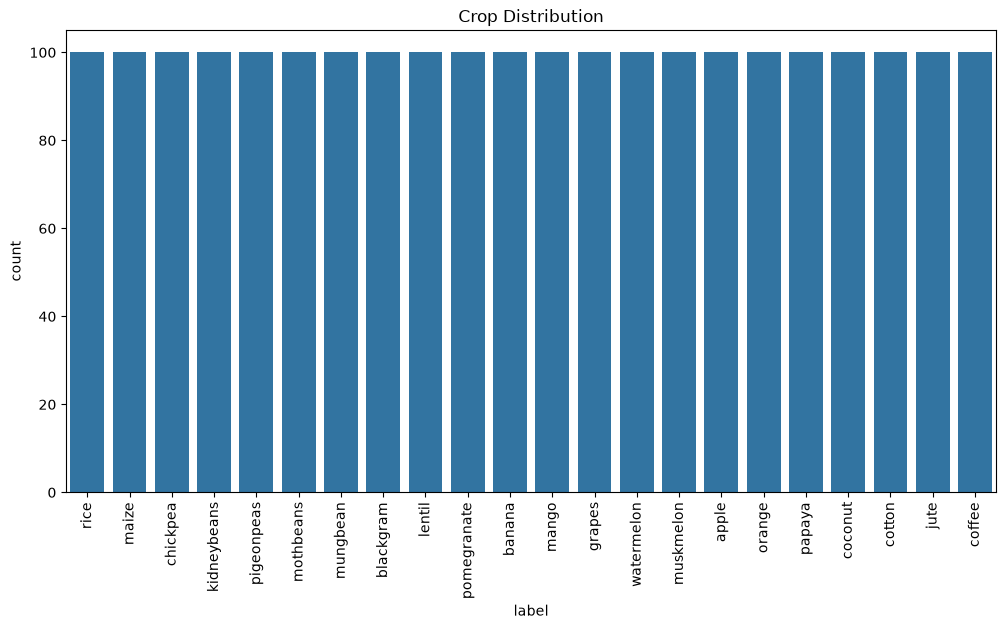

In [21]:
plt.figure(figsize=(12, 6))

sns.countplot(data=df, x='label')

plt.xticks(rotation=90)
plt.title("Crop Distribution")
plt.show()

## 12. Separate Features and Target

Separate the dataset into input features and the target variable.

- `X` contains the seven input features: N, P, K, temperature, humidity, pH, and rainfall.
- `y` contains the target column, `label`, which represents the crop category.

In [22]:
X = df.drop('label', axis=1)
y = df['label']

## 13. View the Features and Target

Display the first five rows of `X` and `y` to check the input features and corresponding crop labels before model training.

In [23]:
print(X.head())
print(y.head())

    N   P   K  temperature   humidity        ph    rainfall
0  90  42  43    20.879744  82.002744  6.502985  202.935536
1  85  58  41    21.770462  80.319644  7.038096  226.655537
2  60  55  44    23.004459  82.320763  7.840207  263.964248
3  74  35  40    26.491096  80.158363  6.980401  242.864034
4  78  42  42    20.130175  81.604873  7.628473  262.717340
0    rice
1    rice
2    rice
3    rice
4    rice
Name: label, dtype: str


## 14. Split the Data and Train the Decision Tree Model

Split the dataset into training and testing sets, using 80% for training and 20% for testing.

- `random_state=42` makes the split reproducible.
- `stratify=y` helps preserve the crop-category proportions in both sets.
- `DecisionTreeClassifier()` creates the Decision Tree classification model.
- `model.fit()` trains the model using the training data.
- `model.predict()` predicts crop labels for the test data.
- `accuracy_score()` calculates the model's accuracy.

In [24]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
model = DecisionTreeClassifier(random_state=42)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", accuracy)

Model Accuracy: 0.9795454545454545


## 15. Evaluate the Model with a Classification Report

Use `classification_report()` to compare the actual test labels (`y_test`) with the predicted labels (`y_pred`).

The report displays precision, recall, F1-score, and support for each crop category.

In [25]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

       apple       1.00      1.00      1.00        20
      banana       1.00      1.00      1.00        20
   blackgram       1.00      0.80      0.89        20
    chickpea       1.00      1.00      1.00        20
     coconut       1.00      1.00      1.00        20
      coffee       1.00      1.00      1.00        20
      cotton       1.00      1.00      1.00        20
      grapes       1.00      1.00      1.00        20
        jute       0.95      0.95      0.95        20
 kidneybeans       1.00      1.00      1.00        20
      lentil       0.86      0.90      0.88        20
       maize       0.95      1.00      0.98        20
       mango       1.00      1.00      1.00        20
   mothbeans       0.86      0.95      0.90        20
    mungbean       1.00      1.00      1.00        20
   muskmelon       1.00      1.00      1.00        20
      orange       1.00      1.00      1.00        20
      papaya       1.00    

## 16. Display the Confusion Matrix

Create a confusion matrix to compare the actual crop labels with the model's predicted crop labels.

- `confusion_matrix()` calculates the matrix.
- `annot=True` displays the values inside the heatmap.
- `fmt='d'` displays the values as integers.
- `cmap='Blues'` uses blue shades for the heatmap.
- The x-axis represents predicted labels, and the y-axis represents actual labels.

The diagonal cells show correct predictions; off-diagonal cells show incorrect predictions.

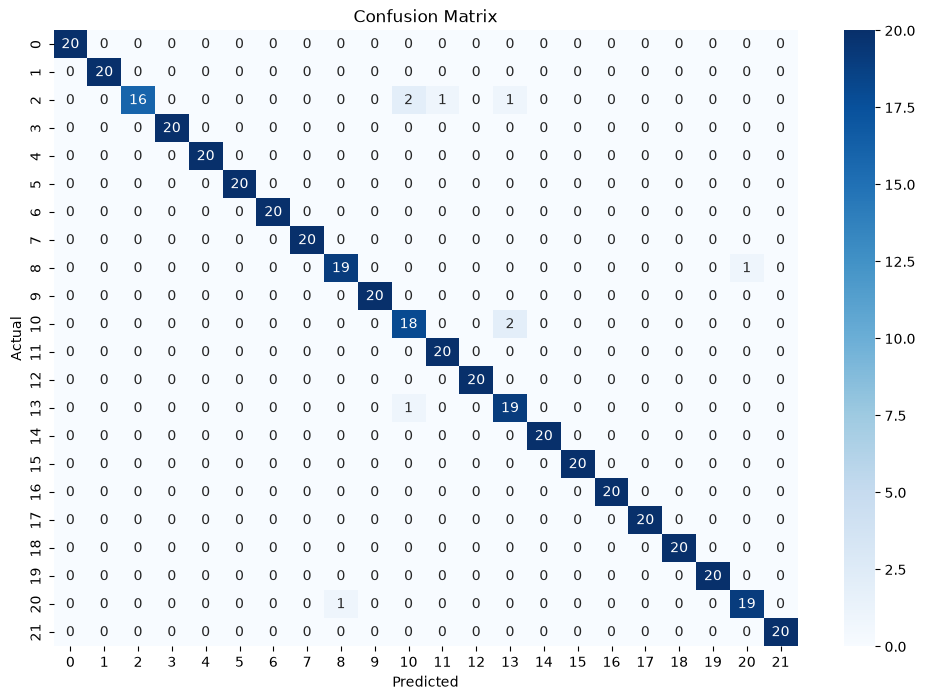

In [18]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(12, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

## 17. Predict a Crop Using New Input Values

Create a new DataFrame containing values for all seven input features.

Pass this data to the trained Decision Tree model using `model.predict()` to get a crop recommendation. The printed result displays the predicted crop category.

In [19]:
new_data = pd.DataFrame({
    'N': [90],
    'P': [42],
    'K': [43],
    'temperature': [20.8],
    'humidity': [82],
    'ph': [6.5],
    'rainfall': [202.9]
})

prediction = model.predict(new_data)

print("Recommended Crop:", prediction[0])

Recommended Crop: rice


## 18. Test the Model with Another Set of Input Values

Create a second new DataFrame with another set of values for the seven input features.

Use the same trained model to predict the crop category for this new input.

In [26]:
new_data2=pd.DataFrame({
    "N":[50],
    "P":[58],
    "K":[70],
    "temperature":[32.7],
    "humidity":[70],
    "ph":[7.2],
    "rainfall":[156.4]
})
prediction1=model.predict(new_data2)
print("Recommended crop:",prediction1[0])


Recommended crop: pigeonpeas
